In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Libraries imported successfully!")

Libraries imported successfully!


# Hybrid Ensemble Approach for Customer Churn Prediction Using SHAP

## 1. Dataset Description and Exploration

In [2]:
df = pd.read_csv("../dataset/customer_churn_dataset-testing-master.csv")


In [4]:
df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0


In [5]:
df.tail(10)

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
64364,64365,48,Female,36,22,4,22,Premium,Annual,342,9,1
64365,64366,26,Female,54,24,2,21,Basic,Annual,165,23,1
64366,64367,64,Male,30,27,9,28,Premium,Annual,884,21,1
64367,64368,51,Male,47,17,10,26,Basic,Annual,544,24,1
64368,64369,45,Male,3,1,5,11,Standard,Annual,218,15,1
64369,64370,45,Female,33,12,6,21,Basic,Quarterly,947,14,1
64370,64371,37,Male,6,1,5,22,Standard,Annual,923,9,1
64371,64372,25,Male,39,14,8,30,Premium,Monthly,327,20,1
64372,64373,50,Female,18,19,7,22,Standard,Monthly,540,13,1
64373,64374,52,Female,45,15,9,25,Standard,Monthly,696,22,1


In [3]:
df.shape

(64374, 12)

In [4]:
rows, columns = df.shape

print("Number of records:", rows)
print("Number of columns:", columns)

Number of records: 64374
Number of columns: 12


In [5]:
df.columns

Index(['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency',
       'Support Calls', 'Payment Delay', 'Subscription Type',
       'Contract Length', 'Total Spend', 'Last Interaction', 'Churn'],
      dtype='str')

In [6]:

df.dtypes

CustomerID           int64
Age                  int64
Gender                 str
Tenure               int64
Usage Frequency      int64
Support Calls        int64
Payment Delay        int64
Subscription Type      str
Contract Length        str
Total Spend          int64
Last Interaction     int64
Churn                int64
dtype: object

In [10]:
df.dtypes.value_counts()

int64    9
str      3
Name: count, dtype: int64

In [11]:
# Checking for missing values

missing_data = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_data

,Missing Values,Percentage
CustomerID,0,0.0
Age,0,0.0
Gender,0,0.0
Tenure,0,0.0
Usage Frequency,0,0.0
Support Calls,0,0.0
Payment Delay,0,0.0
Subscription Type,0,0.0
Contract Length,0,0.0
Total Spend,0,0.0


In [12]:
# Visualize missing values

missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]

if len(missing_counts) == 0:
    print("No missing values found in the dataset.")
else:
    plt.figure(figsize=(10, 5))
    missing_counts.plot(kind="bar")

    plt.title("Missing Values by Feature")
    plt.xlabel("Features")
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

No missing values found in the dataset.


In [13]:
rows_with_missing = df[df.isnull().any(axis=1)]

print("Number of rows conatining missing values:", len(rows_with_missing))

rows_with_missing.head(10)


Number of rows conatining missing values: 0


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn


In [14]:
df.duplicated().sum()

np.int64(0)

In [16]:
df = df.drop_duplicates()

In [15]:
df.shape

(64374, 12)

In [17]:
df.describe()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000
mean,32187.500000,41.970982,31.994827,15.080234,5.400690,17.133952,541.023379,15.498850,0.473685
std,18583.317451,13.924911,17.098234,8.816470,3.114005,8.852211,260.874809,8.638436,0.499311
min,1.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,16094.250000,30.000000,18.000000,7.000000,3.000000,10.000000,313.000000,8.000000,0.000000
50%,32187.500000,42.000000,33.000000,15.000000,6.000000,19.000000,534.000000,15.000000,0.000000
75%,48280.750000,54.000000,47.000000,23.000000,8.000000,25.000000,768.000000,23.000000,1.000000
max,64374.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


In [18]:
df.describe(include="object")

C:\Users\HP\AppData\Local\Temp\ipykernel_14376\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Gender,Subscription Type,Contract Length
count,64374,64374,64374
unique,2,3,3
top,Female,Standard,Monthly
freq,34353,21502,22130


In [19]:
df["Churn"].value_counts()

Churn
0    33881
1    30493
Name: count, dtype: int64

In [20]:
(df["Churn"].value_counts(normalize=True) * 100).round(2)

Churn
0    52.63
1    47.37
Name: proportion, dtype: float64

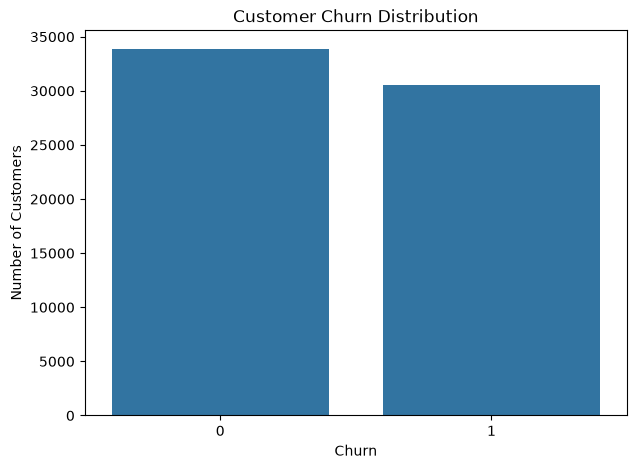

In [21]:
# Visualize customer churn distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

### Observation

The class distribution shows the number of customers who churned and did not churn. The percentage distribution is used to determine whether the target classes are balanced or imbalanced. This observation will help in selecting appropriate evaluation metrics and modelling strategies.